# Compare your data to mobility laws

**Question.** Do the movements in my data follow the regularities reported for human mobility, and what are their parameters?

**You will get** three fitted laws with their parameters and plots: the truncated power law of jump lengths, the universal visitation law (how often people visit places at each distance), and the lognormal distribution of the number of distinct places a person visits per day.

**Prerequisites.** [Measure individual mobility](measure-individual-mobility.md) and [Population measures and flows](population-measures.md).

**Data.** [Brightkite](https://snap.stanford.edu/data/loc-brightkite.html) check-ins (Stanford SNAP, 2008 to 2010): the first 300,000 rows (about 4 MB of the 60 MB file) with `fastmob.data.load_brightkite`, users with at least 100 check-ins (about 306). For the stay-based laws each check-in is treated as a 30-minute stay (an assumption). The notebook stops if the download fails.

In [1]:
%pip install -q 'fastmob>=0.3.4' pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## Load and clean

As in the previous notebooks, we drop placeholder and invalid coordinates and users with fewer than 100 check-ins.

In [2]:
import fastmob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fastmob.data import load_brightkite
from fastmob.measures import fitting

raw = load_brightkite(max_rows=300_000).to_pandas()

raw = raw[~(((raw["lat"] == 0) & (raw["lng"] == 0)) | (raw["lat"].abs() >= 90))]
counts = raw.groupby("uid").size()
checkins = (
    raw[raw["uid"].isin(counts[counts >= 100].index)]
    .sort_values(["uid", "datetime"])
    .reset_index(drop=True)
)
print(len(checkins), "check-ins by", checkins["uid"].nunique(), "users")

283543 check-ins by 306 users


## Law 1: jump lengths follow a truncated power law

Human jump lengths are heavy-tailed: short moves are common, long ones rare but not negligible, up to a cutoff. `fit_values_to_truncated_powerlaw` fits $P(\Delta r) \propto (\Delta r + \Delta r_0)^{-\beta} \exp(-\Delta r / \kappa)$ to a log-spaced histogram of positive jumps and returns the four parameters `(c, r0, beta, kappa)` plus the histogram it fitted. `log_truncated_powerlaw` evaluates the fitted curve.

In [3]:
jumps = fastmob.jump_lengths(checkins)
values = np.concatenate(jumps["jump_lengths"].to_list())
values = values[np.isfinite(values) & (values > 0)]
params, x, y = fitting.fit_values_to_truncated_powerlaw(values)
curve = np.exp(fitting.log_truncated_powerlaw(x, *params))

c, r0, beta, kappa = params
print(f"{len(values):,} positive jumps, median {np.median(values):.1f} km")
print(f"beta = {beta:.2f}, r0 = {r0:.2f} km, kappa = {kappa:,.0f} km")

133,372 positive jumps, median 7.1 km
beta = 1.61, r0 = 2.40 km, kappa = 143,421 km


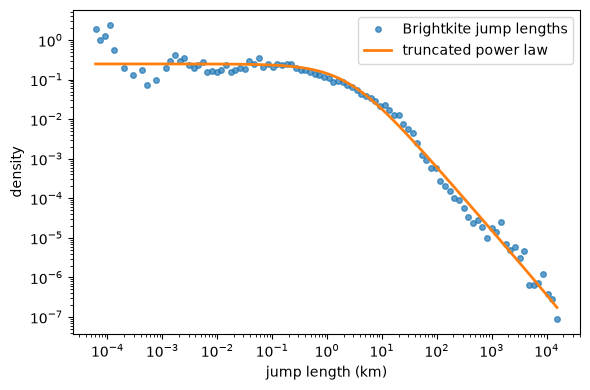

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(x, y, "o", ms=4, alpha=0.7, label="Brightkite jump lengths")
ax.loglog(x, curve, "-", lw=2, label="truncated power law")
ax.set_xlabel("jump length (km)")
ax.set_ylabel("density")
ax.legend()
fig.tight_layout()
plt.show()

There are 133,372 positive jumps with a median of 7.1 km. The fit gives beta = 1.61 and r0 = 2.4 km: below a few kilometres the density is flat, above it falls as a power law of about -1.6. The cutoff kappa (143,421 km) is far larger than the size of the Earth, so no cutoff is detectable here and the curve is effectively a plain power law up to the longest jumps (about 15,000 km). The curve follows the data over seven orders of magnitude; the points at the shortest lengths (below about 1 m) are noisy.

## Law 2: the universal visitation law

The visitation law (Schläpfer et al., *Nature* 2021) describes the density $\rho$ of visitors (visitors per km²) of places that are visited with frequency $f$ from distance $r$: it falls as a power of the product $rf$, $\rho = \mu (rf)^{-\eta}$. `fit_visitation_law` takes stays (here the 30-minute check-in stays on an H3 grid of resolution 8), computes the distance $r$ of each place from the person's home and its distinct-day visit frequency $f$, bins the values and fits $\eta$ and $\mu$ on a log-log scale. The result is a `VisitationLawFit` with the per-user-place `data`, the aggregate `spectrum` that was fitted, and the parameters.

In [5]:
stays = fastmob.Staypoints(
    pd.DataFrame(
        {
            "uid": checkins["uid"],
            "lat": checkins["lat"],
            "lng": checkins["lng"],
            "started_at": checkins["datetime"],
            "finished_at": checkins["datetime"] + pd.Timedelta(minutes=30),
        }
    )
)
places, stays_at = stays.generate_global_locations(h3_resolution=8)
visitation = fitting.fit_visitation_law(stays_at, locations=places)

print(
    f"eta = {visitation.eta:.2f}, mu = {visitation.mu:.2f}, R2 = {visitation.r2:.2f}; {len(visitation.data)} user-place pairs, {len(visitation.spectrum)} spectrum points"
)
visitation.spectrum.head()

eta = 0.77, mu = 0.20, R2 = 0.97; 32225 user-place pairs, 30 spectrum points


,rf,rho
0,0.637364,0.363783
1,1.035673,0.337959
2,1.682898,0.177953
3,2.734594,0.117504
4,4.443529,0.065546


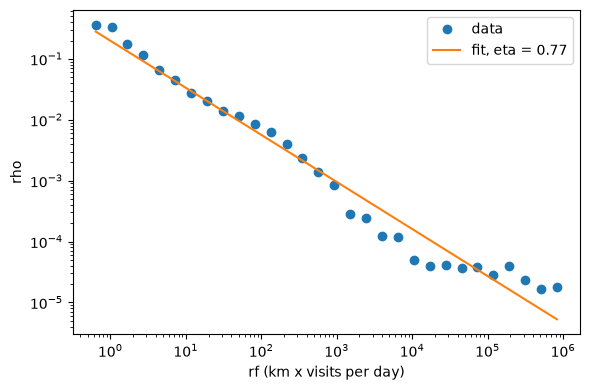

In [6]:
spectrum = visitation.spectrum
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(spectrum["rf"], spectrum["rho"], "o", label="data")
ax.loglog(
    spectrum["rf"],
    visitation.mu * spectrum["rf"] ** -visitation.eta,
    "-",
    label=f"fit, eta = {visitation.eta:.2f}",
)
ax.set_xlabel("rf (km x visits per day)")
ax.set_ylabel("rho")
ax.legend()
fig.tight_layout()
plt.show()

The fitted exponent is eta = 0.77 with R² = 0.97 on 30 spectrum points. The line follows the data over the middle of the range; for rf above about 10⁵ (km per visit per day) the data flatten and lie above the line, so the power law describes the bulk and not the far tail. The exponent is not directly comparable with the published value: that is estimated from mobile-phone data, and check-ins from a social network with an assumed 30-minute stay, in a coarser region of the rf range, can give a different exponent. Compare with the literature for your own kind of data before interpreting eta.

## Law 3: distinct places per day are lognormal

`fit_daily_location_lognormal` counts, for each person and day, the number of distinct places visited, and fits a lognormal distribution to those counts. It returns the values (1, 2, 3, ... places), their observed probability, and the fitted $\mu$ and $\sigma$ of the lognormal.

In [7]:
n_places, observed, mu, sigma = fitting.fit_daily_location_lognormal(
    stays_at, locations=places
)

print(
    f"mu = {mu:.2f}, sigma = {sigma:.2f}; share of person-days with 1 place: {observed[0]:.0%}, with 2 places: {observed[1]:.0%}"
)

mu = 0.44, sigma = 0.54; share of person-days with 1 place: 55%, with 2 places: 25%


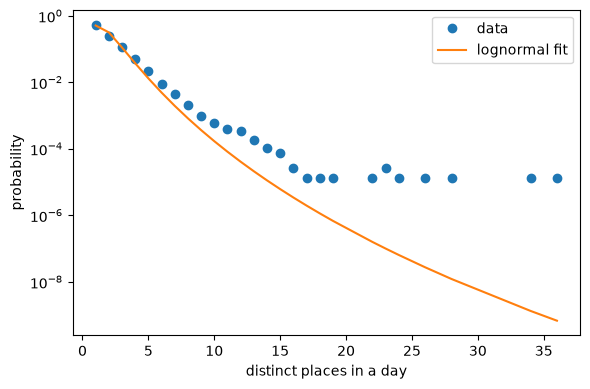

In [8]:
k = np.array(n_places)
pdf = np.exp(-((np.log(k) - mu) ** 2) / (2 * sigma**2)) / (
    k * sigma * np.sqrt(2 * np.pi)
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(k, observed, "o", label="data")
ax.semilogy(k, pdf / pdf.sum() * sum(observed), "-", label="lognormal fit")
ax.set_xlabel("distinct places in a day")
ax.set_ylabel("probability")
ax.legend()
fig.tight_layout()
plt.show()

Fitted mu = 0.44 and sigma = 0.54. 55% of the person-days have a single place and 25% have two. The lognormal follows the first few points but falls well below the data from about 8 places a day on: the observed tail is heavier, with a few person-days of 20 to 35 places. For these data a heavier-tailed distribution would fit better.

## Interpretation and limits

- A fitted exponent is only meaningful with an uncertainty and a stated range. These fits report point estimates from a log-spaced histogram; they do not give confidence intervals, so do not over-read differences in the second decimal.
- Check-in data over-represent short, social, urban movement and skip travel that is not checked in. Compare with literature values only for similar data types (mobile-phone, GPS or check-in data give different parameters).
- The visitation-law and lognormal fits depend on the assumed 30-minute stay and the grid resolution (H3 level 8).
- Fit quality here is judged by eye and by $R^2$ of the spectrum; it is not a goodness-of-fit test against alternatives (such as a plain power law or exponential).

## Next steps

- Compare the fitted law with a model, and quantify the difference: [Fit and compare distributions](fit-and-evaluate.md).
- Generate trajectories that follow these laws: [Generate mobility with models](generate-mobility.md).

## Related API

[`fit_values_to_truncated_powerlaw`](../reference/fitting.md#fastmob.measures.fitting.fit_values_to_truncated_powerlaw) ·
[`log_truncated_powerlaw`](../reference/fitting.md#fastmob.measures.fitting.log_truncated_powerlaw) ·
[`fit_visitation_law`](../reference/fitting.md#fastmob.measures.fitting.fit_visitation_law) ·
[`VisitationLawFit`](../reference/fitting.md#fastmob.measures.fitting.VisitationLawFit) ·
[`fit_daily_location_lognormal`](../reference/fitting.md#fastmob.measures.fitting.fit_daily_location_lognormal)
